# 02_Data_Cleaning — Text Audit, Cleaning Rules, Deduplication & Split

In [1]:
import os
if 'notebooks' in os.getcwd():
    os.chdir('..')
os.makedirs('output', exist_ok=True)
print(f'Working directory: {os.getcwd()}')

Working directory: D:\Data analyst\Portfolio\Banque\bank-complaint-routing-nlp


In [2]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.width', 200)
print('✓ Libraries loaded')

✓ Libraries loaded


In [3]:
A = {n: pd.read_csv(f'reports/phase2a/{n}.csv') for n in
     ['A1_date_shapes', 'A3_brace_shapes', 'A4_pattern_coverage', 'A5_length_by_service', 'A7_dedup_preview',
      'A9c_artifact_coverage']}
rules = pd.read_csv('reports/phase2b/rules_counts.csv')
split = pd.read_csv('reports/phase2b/split_by_service.csv')
man = json.load(open('data/processed/MANIFEST.json', encoding='utf-8'))
print(f"Scope (Jan–Jul 2026, frozen mapping): {int(A['A7_dedup_preview']['n_rows_scope'].iloc[0]):,} narratives")

Scope (Jan–Jul 2026, frozen mapping): 116,449 narratives


## 1. Text Audit (masks, dates, amounts, artefacts)

In [4]:
print('Pattern coverage (%):'); print(A['A4_pattern_coverage'].to_string(index=False))
print('\nDate shapes (top 5):'); print(A['A1_date_shapes'].head().to_string(index=False))
print('\nBrace shapes (top 5):'); print(A['A3_brace_shapes'].head().to_string(index=False))
print('\nArtefacts:'); print(A['A9c_artifact_coverage'].to_string(index=False))

Pattern coverage (%):
 n_narratives  pct_with_date_pattern  pct_with_other_xseq  pct_with_brace
       116449                  26.83                81.83           42.26

Date shapes (top 5):
     shape  n_occurrences
XX/XX/XXXX         117896
XX/XX/9999           4663
  XX/XX/99            535
99/99/9999             38
  99/99/99             26

Brace shapes (top 5):
      shape  n_occurrences
  {$999.99}          51367
 {$9999.99}          48650
   {$99.99}          19544
{$99999.99}          16712
    {$9.99}           7612

Artefacts:
 n_narratives  n_bytes_prefix  n_bytes_prefix_and_quote_end  n_with_date_letters  n_with_angle_bracket  n_with_literal_escape
       116449             741                           543                30096                 29805                    757


## 2. Cleaning Rules R1–R8

                    rule  n_narratives
         R1_bytes_prefix           741
      R2_literal_escapes           756
                R3_dates         56336
              R4_amounts         49182
R5_glued_xseq_narratives          4621
                 R5_xseq         92131
            R6_collapsed         61595
    R8_dropped_no_letter            11


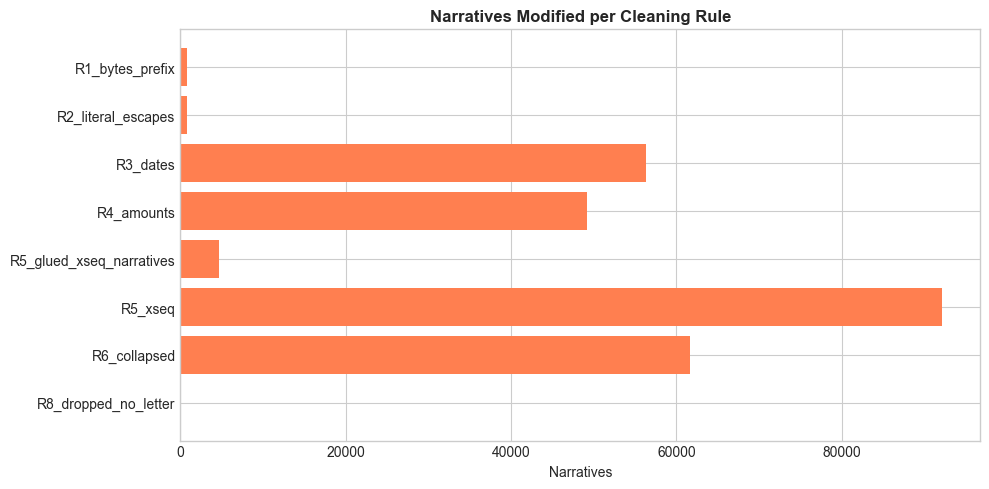

✓ Saved: 02_cleaning_rules.png


In [5]:
print(rules.to_string(index=False))
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(rules['rule'][::-1], rules['n_narratives'][::-1], color='coral')
ax.set_title('Narratives Modified per Cleaning Rule', fontsize=12, fontweight='bold')
ax.set_xlabel('Narratives')
plt.tight_layout()
plt.savefig('output/02_cleaning_rules.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 02_cleaning_rules.png')

## 3. Deduplication Funnel

In [6]:
scope = int(A['A7_dedup_preview']['n_rows_scope'].iloc[0])
r8 = int(rules.loc[rules['rule'] == 'R8_dropped_no_letter', 'n_narratives'].iloc[0])
final = man['all']['rows']
funnel = pd.DataFrame({'step': ['Scope', 'After R8 (no letter)', 'After dedup on cleaned text'],
                       'rows': [scope, scope - r8, final]})
print(funnel.to_string(index=False))
print(f'\nRemoved by deduplication: {scope - r8 - final:,}')

                       step   rows
                      Scope 116449
       After R8 (no letter) 116438
After dedup on cleaned text 106307

Removed by deduplication: 10,131


## 4. Stratified Split 70/15/15

                 service  train  val  test  total  train_pct  val_pct  test_pct
        Comptes & Dépôts  14906 3194  3194  21294       70.0     15.0     15.00
       Crédit immobilier   5438 1165  1166   7769       70.0     15.0     15.01
Crédits aux particuliers   9987 2140  2140  14267       70.0     15.0     15.00
               Monétique  15169 3250  3251  21670       70.0     15.0     15.00
            Recouvrement  22084 4732  4732  31548       70.0     15.0     15.00
  Transferts & Paiements   6831 1464  1464   9759       70.0     15.0     15.00


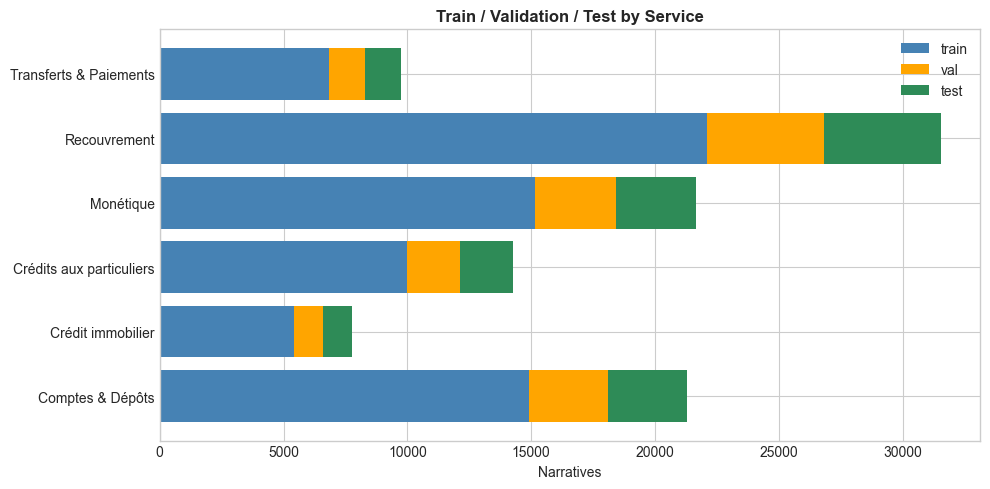

✓ Saved: 02_split_by_service.png


In [7]:
split['train_pct'] = (100 * split['train'] / split['total']).round(2)
split['val_pct'] = (100 * split['val'] / split['total']).round(2)
split['test_pct'] = (100 * split['test'] / split['total']).round(2)
print(split.to_string(index=False))
fig, ax = plt.subplots(figsize=(10, 5))
bottom = np.zeros(len(split))
for col, color in [('train', 'steelblue'), ('val', 'orange'), ('test', 'seagreen')]:
    ax.barh(split['service'], split[col], left=bottom, color=color, label=col)
    bottom += split[col].to_numpy()
ax.set_title('Train / Validation / Test by Service', fontsize=12, fontweight='bold')
ax.set_xlabel('Narratives'); ax.legend()
plt.tight_layout()
plt.savefig('output/02_split_by_service.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 02_split_by_service.png')

## 5. Language Check (heuristic, no filtering)

In [8]:
print(pd.read_csv('reports/phase2b/language_by_service.csv').to_string(index=False))
print('\nNote: unvalidated stopword heuristic — flags are hints, not labels.')

                 service  english_likely  non_english_suspect  spanish_suspect  too_short_to_judge
        Comptes & Dépôts           21231                   37                0                  26
       Crédit immobilier            7752                   14                0                   3
Crédits aux particuliers           14211                   28                0                  28
               Monétique           21560                   51                1                  58
            Recouvrement           31255                  167                2                 124
  Transferts & Paiements            9740                   13                1                   5

Note: unvalidated stopword heuristic — flags are hints, not labels.
